# About the data set

### Context

* "Predict behavior to retain customers. You can analyze all relevant customer data and develop focused customer retention programs." [IBM Sample Data Sets]

### Content

Each row represents a customer, each column contains customer’s attributes described on the column Metadata.

The data set includes information about:

* Customers who left within the last month – the column is called Churn

* Services that each customer has signed up for – phone, multiple lines, internet, online security, online backup, device protection, tech support, and streaming TV and movies

* Customer account information – how long they’ve been a customer, contract, payment method, paperless billing, monthly charges, and total charges

* Demographic info about customers – gender, age range, and if they have partners and dependents

# data overview

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [4]:
df = pd.read_csv("D:/ML Churn model with FastAPI, MLFlow, Docker, & AWS/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv")

In [5]:
df.shape

(7043, 21)

In [6]:
pd.set_option('display.max_columns', None)    #show all columns
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


tenure's mean > median indecates a slight right skewed shape meaning most of the values are on the lower half,
and the opposite in monthly charges.

In [8]:
df.describe(include='object').T

C:\Users\youssef\AppData\Local\Temp\ipykernel_15260\1760094569.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object').T


,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [10]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
# numeric column that is str data type

In [11]:
df['TotalCharges'].describe()

count    7032.000000
mean     2283.300441
std      2266.771362
min        18.800000
25%       401.450000
50%      1397.475000
75%      3794.737500
max      8684.800000
Name: TotalCharges, dtype: float64

Churn
No     5174
Yes    1869
Name: count, dtype: int64


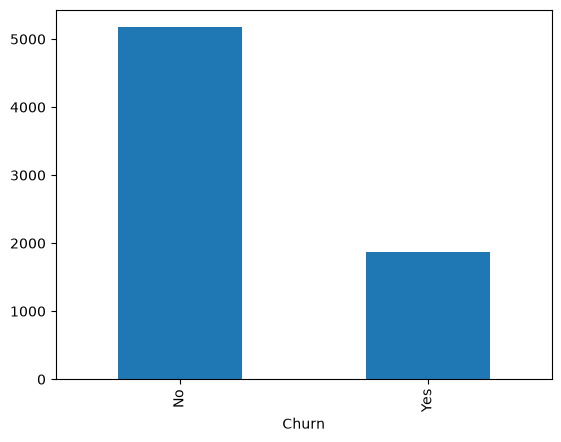

In [12]:
df['Churn'].value_counts().plot(kind='bar')
print(df['Churn'].value_counts())  # class imbalance check

# data analysis

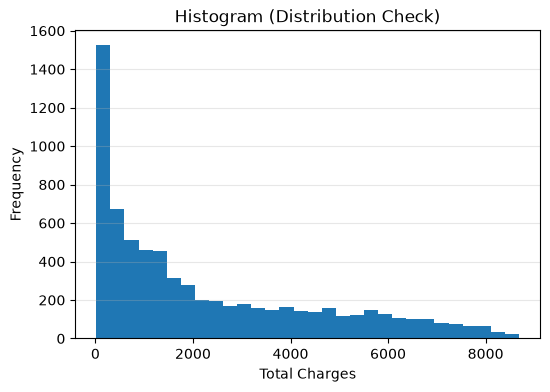

In [13]:
plt.figure(figsize=(6, 4))
plt.hist(df['TotalCharges'], bins=30)

plt.title('Histogram (Distribution Check)')
plt.xlabel('Total Charges')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)
plt.show()

Text(0.5, 1.0, 'Churned Customers by Total Charges')

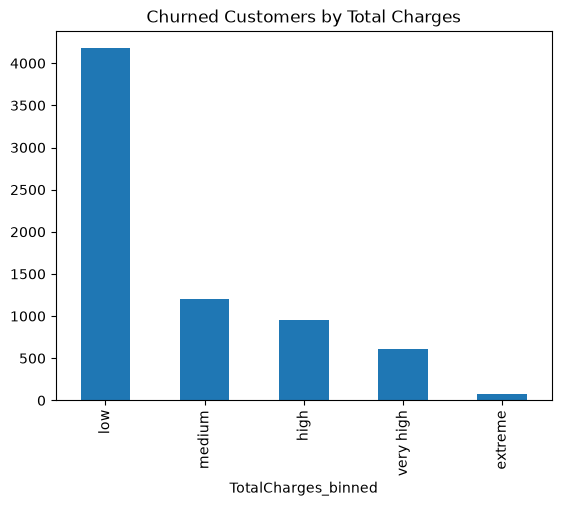

In [14]:
# let's check how many customers churned based on their total charges

bins = [0, 2000, 4000, 6000, 8000, np.inf]  # define the bins for TotalCharges
labels = ["low", "medium", "high", "very high", "extreme"]  # define the labels for the bins
df['TotalCharges_binned'] = pd.cut(df['TotalCharges'], bins=bins,
                                    labels=labels, right=False)  # create a new column with binned values

df['TotalCharges_binned'].value_counts().plot(kind='bar')
plt.title('Churned Customers by Total Charges')

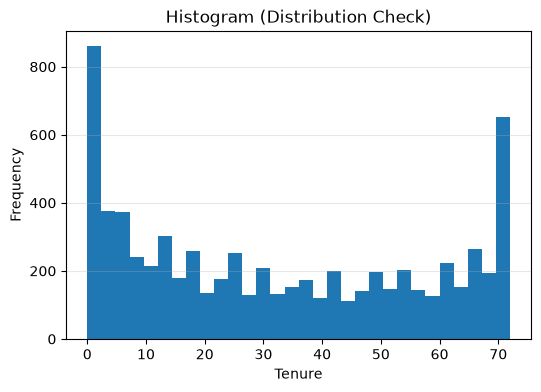

In [15]:
plt.figure(figsize=(6, 4))
plt.hist(df['tenure'], bins=30)

plt.title('Histogram (Distribution Check)')
plt.xlabel('Tenure')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)
plt.show()

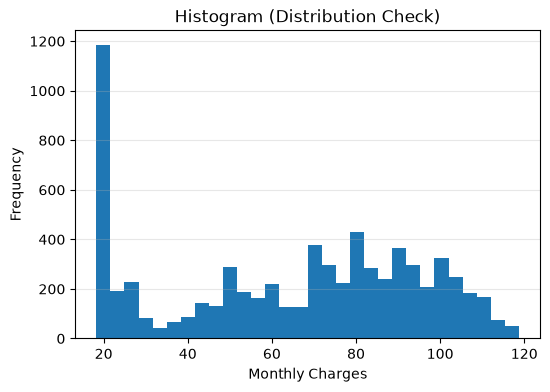

In [16]:

plt.figure(figsize=(6, 4))
plt.hist(df['MonthlyCharges'], bins=30)

plt.title('Histogram (Distribution Check)')
plt.xlabel('Monthly Charges')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=0.3)
plt.show()

In [17]:
contract_churn = df.groupby(['Contract', 'Churn']).size().unstack(fill_value=0)

contract_churn

Churn,No,Yes
Contract,,
Month-to-month,2220,1655
One year,1307,166
Two year,1647,48


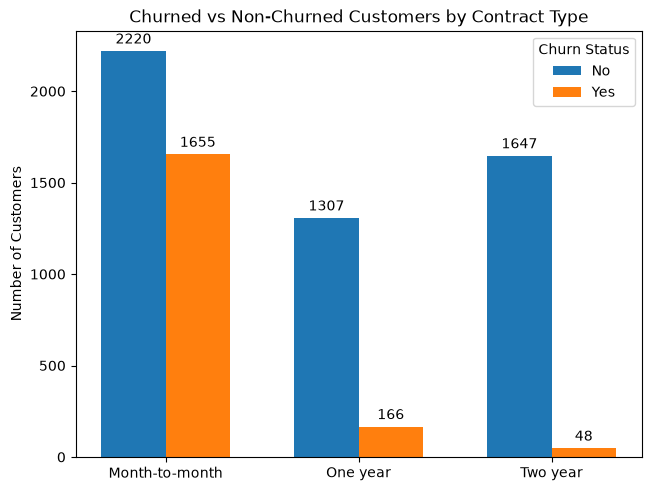

In [18]:

fig, ax = plt.subplots(layout='constrained')

res = ax.grouped_bar(contract_churn, tick_labels=contract_churn.index, group_spacing=1)
for container in res.bar_containers:
    ax.bar_label(container, padding=3)

ax.set_ylabel('Number of Customers')
ax.set_title('Churned vs Non-Churned Customers by Contract Type')
ax.legend(loc='upper left', ncols=2, title='Churn Status')
ax.legend(title='Churn Status')

plt.show()

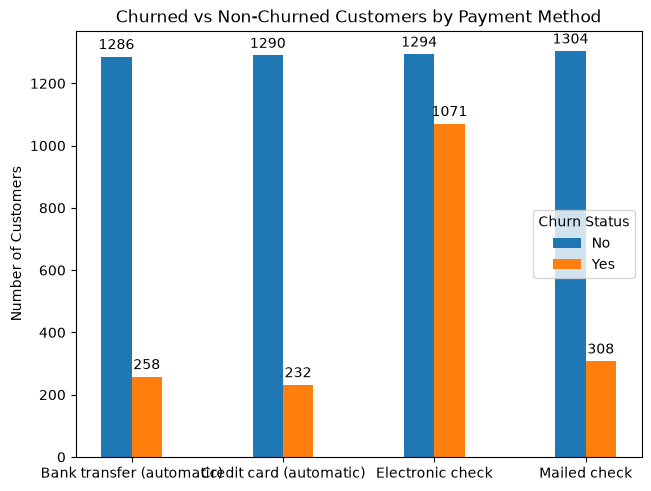

In [19]:
PaymentMethod_churn = df.groupby(['PaymentMethod', 'Churn']).size().unstack(fill_value=0)

fig, ax = plt.subplots(layout='constrained')

res = ax.grouped_bar(PaymentMethod_churn, tick_labels=PaymentMethod_churn.index, group_spacing=3)
for container in res.bar_containers:
    ax.bar_label(container, padding=3)

ax.set_ylabel('Number of Customers')
ax.set_title('Churned vs Non-Churned Customers by Payment Method')
ax.legend(loc='upper left', ncols=2, title='Churn Status')
ax.legend(title='Churn Status')

plt.show()

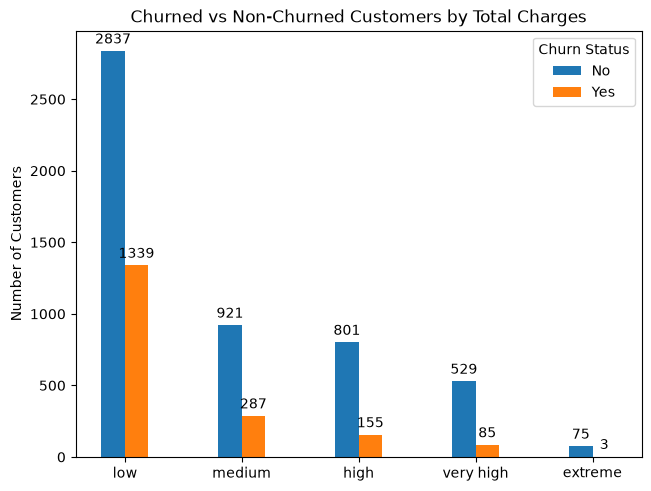

In [20]:
total_charges_churn = df.groupby(['TotalCharges_binned', 'Churn']).size().unstack(fill_value=0)

fig, ax = plt.subplots(layout='constrained')

res = ax.grouped_bar(total_charges_churn, tick_labels=total_charges_churn.index, group_spacing=3)
for container in res.bar_containers:
    ax.bar_label(container, padding=3)

ax.set_ylabel('Number of Customers')
ax.set_title('Churned vs Non-Churned Customers by Total Charges')
ax.legend(loc='upper left', ncols=2, title='Churn Status')
ax.legend(title='Churn Status')

plt.show()

# preprocessing


In [21]:
df.describe(include='object').T

C:\Users\youssef\AppData\Local\Temp\ipykernel_15260\1760094569.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object').T


,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


since most categorical columns have 2-3 unique values, one hot encoder will be the best option

In [22]:
binary_cols = ["gender", 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling', 'Churn']
df[binary_cols] = df[binary_cols].replace({'Yes': 1, 'No': 0, 'Female': 1, 'Male': 0}, inplace=True)

C:\Users\youssef\AppData\Local\Temp\ipykernel_15260\2825224879.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df[binary_cols] = df[binary_cols].replace({'Yes': 1, 'No': 0, 'Female': 1, 'Male': 0}, inplace=True)


In [23]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalCharges_binned
0,7590-VHVEG,1,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0,low
1,5575-GNVDE,0,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0,low
2,3668-QPYBK,0,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1,low
3,7795-CFOCW,0,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0,low
4,9237-HQITU,1,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1,low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,0,0,1,1,24,1,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,One year,1,Mailed check,84.80,1990.50,0,low
7039,2234-XADUH,1,0,1,1,72,1,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,1,Credit card (automatic),103.20,7362.90,0,very high
7040,4801-JZAZL,1,0,1,1,11,0,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,1,Electronic check,29.60,346.45,0,low
7041,8361-LTMKD,0,1,1,0,4,1,Yes,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Mailed check,74.40,306.60,1,low


In [24]:
categorical_cols = ['MultipleLines', 'InternetService', 'OnlineSecurity',
                    'OnlineBackup', 'DeviceProtection', 'TechSupport', 
                    'StreamingTV', 'StreamingMovies', 'Contract', 'PaymentMethod']



In [25]:
df = pd.get_dummies(df, columns=categorical_cols, drop_first=True)
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,TotalCharges_binned,MultipleLines_No phone service,MultipleLines_Yes,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,7590-VHVEG,1,0,1,0,1,0,1,29.85,29.85,0,low,True,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,True,False
1,5575-GNVDE,0,0,0,0,34,1,0,56.95,1889.50,0,low,False,False,False,False,False,True,False,False,False,True,False,False,False,False,False,False,True,False,False,False,True
2,3668-QPYBK,0,0,0,0,2,1,1,53.85,108.15,1,low,False,False,False,False,False,True,False,True,False,False,False,False,False,False,False,False,False,False,False,False,True
3,7795-CFOCW,0,0,0,0,45,0,0,42.30,1840.75,0,low,True,False,False,False,False,True,False,False,False,True,False,True,False,False,False,False,True,False,False,False,False
4,9237-HQITU,1,0,0,0,2,1,1,70.70,151.65,1,low,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,0,0,1,1,24,1,1,84.80,1990.50,0,low,False,True,False,False,False,True,False,False,False,True,False,True,False,True,False,True,True,False,False,False,True
7039,2234-XADUH,1,0,1,1,72,1,1,103.20,7362.90,0,very high,False,True,True,False,False,False,False,True,False,True,False,False,False,True,False,True,True,False,True,False,False
7040,4801-JZAZL,1,0,1,1,11,0,1,29.60,346.45,0,low,True,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False,False,False,False,True,False
7041,8361-LTMKD,0,1,1,0,4,1,1,74.40,306.60,1,low,False,True,True,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,True


In [26]:
df = df.drop(['customerID', 'TotalCharges_binned'], axis=1)

In [27]:
booleans = df.select_dtypes(include='bool').columns
df[booleans] = df[booleans].astype('int')

In [28]:
df[binary_cols] = df[binary_cols].astype('int')

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 31 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   gender                                 7043 non-null   int64  
 1   SeniorCitizen                          7043 non-null   int64  
 2   Partner                                7043 non-null   int64  
 3   Dependents                             7043 non-null   int64  
 4   tenure                                 7043 non-null   int64  
 5   PhoneService                           7043 non-null   int64  
 6   PaperlessBilling                       7043 non-null   int64  
 7   MonthlyCharges                         7043 non-null   float64
 8   TotalCharges                           7032 non-null   float64
 9   Churn                                  7043 non-null   int64  
 10  MultipleLines_No phone service         7043 non-null   int64  
 11  MultipleLines_Y

## correlation


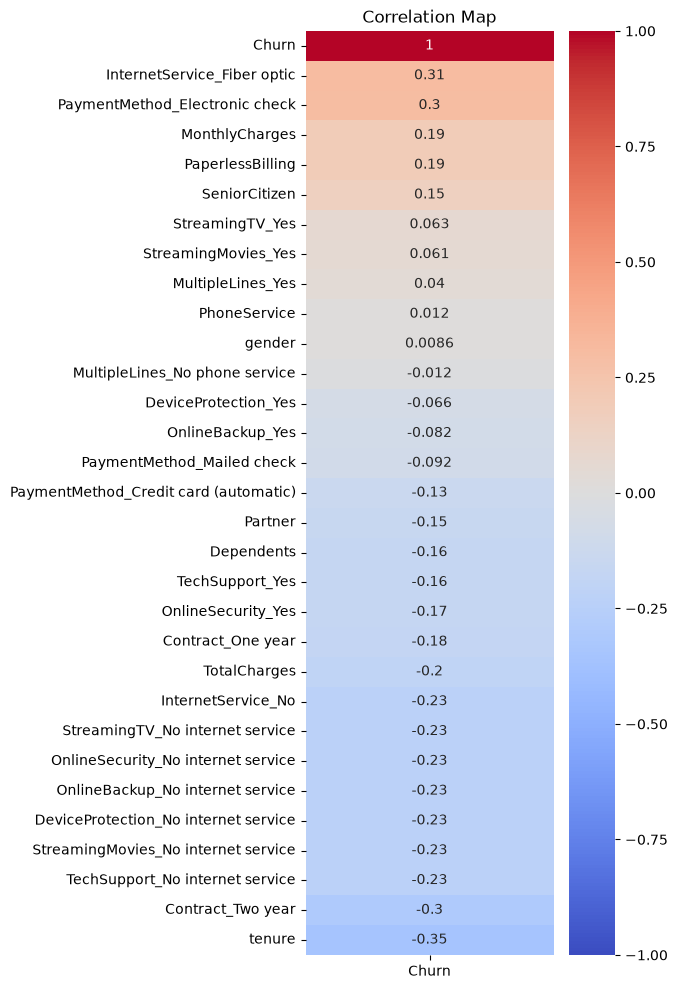

In [31]:
import seaborn as sns

correlation_matrix = df.corr(numeric_only='True')

churn_correlation = correlation_matrix[['Churn']].sort_values(by = 'Churn', ascending=False)

plt.figure(figsize=(4, 12))
sns.heatmap(churn_correlation, annot=True,
            cmap='coolwarm',
            cbar=True,
            vmin=-1, 
            vmax=1,)

plt.title("Correlation Map")
plt.show()

customers with fiber optic and electronic check payment are more likely to churn,
on the other hand, customers with two year contract aren't likely to churn

## VIF check

In [32]:
# We need to drop redundant columns before running VIF
df['No_internet_service'] = (
    df['OnlineSecurity_No internet service'] |
    df['OnlineBackup_No internet service'] |
    df['DeviceProtection_No internet service'] |
    df['TechSupport_No internet service'] |
    df['StreamingTV_No internet service'] |
    df['StreamingMovies_No internet service']
).astype(int)

# Drop the original redundant dummies
drop_cols = [col for col in df.columns if 'No internet service' in col]
df = df.drop(columns=drop_cols)

# Handle PhoneService redundancy
if 'MultipleLines_No phone service' in df.columns:
    df['No_phone_service'] = df['MultipleLines_No phone service'].astype(int)
    df = df.drop(columns=['MultipleLines_No phone service'])

In [33]:
X = df.drop(columns=['Churn'])
bool_cols = X.select_dtypes(include='bool').columns
X[bool_cols] = X[bool_cols].astype(int)

In [34]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Remove rows with missing or infinite values
X = X.replace([np.inf, -np.inf], np.nan)
X = X.dropna()

vif_data = pd.DataFrame()
vif_data['feature'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
vif_data = vif_data.sort_values(by='VIF', ascending=False)

print(vif_data)

C:\Users\youssef\AppData\Local\Temp\ipykernel_15260\245510218.py:9: UserWarning: The design matrix is poorly conditioned (condition number=7.52e+15). VIF calculations may be numerically unstable.
  vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
d:\ML Churn model with FastAPI, MLFlow, Docker, & AWS\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
d:\ML Churn model with FastAPI, MLFlow, Docker, & AWS\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
d:\ML Churn model with FastAPI, MLFlow, Docker, & AWS\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is r

                                  feature           VIF
5                            PhoneService  1.000800e+15
23                    No_internet_service  1.000800e+15
24                       No_phone_service  1.000800e+15
11                     InternetService_No  1.000800e+15
7                          MonthlyCharges  8.660896e+02
10            InternetService_Fiber optic  1.485008e+02
17                    StreamingMovies_Yes  2.415639e+01
16                        StreamingTV_Yes  2.408002e+01
8                            TotalCharges  1.081149e+01
4                                  tenure  7.584453e+00
9                       MultipleLines_Yes  7.289761e+00
14                   DeviceProtection_Yes  6.924754e+00
13                       OnlineBackup_Yes  6.796678e+00
15                        TechSupport_Yes  6.476508e+00
12                     OnlineSecurity_Yes  6.338349e+00
19                      Contract_Two year  2.652328e+00
21         PaymentMethod_Electronic check  1.976

d:\ML Churn model with FastAPI, MLFlow, Docker, & AWS\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
d:\ML Churn model with FastAPI, MLFlow, Docker, & AWS\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
d:\ML Churn model with FastAPI, MLFlow, Docker, & AWS\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


* Clearly we can see there's multicolinearity between features
* So either we need to drop some features or use regularization techniques like Lasso or Ridge regression to handle this
Or use tree based models which are less sensitive to multicollinearity
* In decision trees, splits are based on feature importance for reducing impurity — redundant features just compete, but won’t cause unstable predictions.

# Modeling

In [35]:
# We have a class imbalance problem
# Given your imbalance (27% churners), class weighting + threshold tuning is probably enough — no need for aggressive oversampling yet.
df['Churn'].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

In churn prediction, recall (and metrics derived from it, like F1) is usually the most important — here’s why:

Business context Churn prediction is asymmetric in cost:

* False Negative (FN): You predict a customer will not churn, but they actually leave → you miss the chance to intervene and keep them.

* False Positive (FP): You predict a customer will churn, but they stay → you might spend some retention resources unnecessarily.

* Missing churners (FN) usually costs more than wrongly targeting a loyal customer.

Typical priority

* If retention campaigns are cheap → prioritize recall (catch every possible churner).
* If retention campaigns are expensive → balance precision and recall using F1 score or a precision-recall trade-off.
* If business wants a ranking of churn risk → use ROC-AUC or PR-AUC to evaluate the model.

In [36]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
import lightgbm as lgb
from sklearn.metrics import classification_report
import pandas as pd
import time

# Prepare data
X = df.drop(columns=['Churn'])
y = df['Churn']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

THRESHOLD = 0.3  # lower than 0.5 to boost recall (see next to choose the right value)

## Random Forest

In [37]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

rf = RandomForestClassifier(
    n_estimators=300,
    class_weight='balanced',   # handles imbalance for you
    random_state=42,
    n_jobs=-1
)
rf.fit(X_train, y_train)

proba = rf.predict_proba(X_test)[:, 1]
y_pred = (proba >= THRESHOLD).astype(int)

print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

           0      0.924     0.660     0.770      1035
           1      0.475     0.850     0.609       374

    accuracy                          0.710      1409
   macro avg      0.699     0.755     0.690      1409
weighted avg      0.805     0.710     0.727      1409



In [38]:
# testing different thresholds for RandomForest
from sklearn.metrics import precision_score, recall_score, f1_score

proba = rf.predict_proba(X_test)[:, 1]

print("Threshold tuning for RandomForest")

print(f"{'Thresh':<8}{'Prec_1':<8}{'Rec_1':<8}{'F1_1':<8}")
for thresh in [0.25, 0.30, 0.35, 0.40, 0.45, 0.50]:
    preds = (proba >= thresh).astype(int)
    prec = precision_score(y_test, preds, pos_label=1)
    rec = recall_score(y_test, preds, pos_label=1)
    f1 = f1_score(y_test, preds, pos_label=1)
    print(f"{thresh:<8}{prec:<8.3f}{rec:<8.3f}{f1:<8.3f}")

Threshold tuning for RandomForest
Thresh  Prec_1  Rec_1   F1_1    
0.25    0.449   0.877   0.594   
0.3     0.475   0.850   0.609   
0.35    0.502   0.816   0.622   
0.4     0.513   0.751   0.610   
0.45    0.524   0.687   0.595   
0.5     0.554   0.655   0.600   


* at threshold = 3, we are catching 85% of churners

## light GBM

In [39]:
from lightgbm import LGBMClassifier
from sklearn.metrics import classification_report
import time

lgbm = LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

# Training timer
start_train = time.time()
lgbm.fit(X_train, y_train)
train_time = time.time() - start_train
print(f"⏱ Training time: {train_time:.2f} seconds")

# Prediction timer
start_pred = time.time()
proba = lgbm.predict_proba(X_test)[:, 1]
y_pred = (proba >= THRESHOLD).astype(int)
pred_time = time.time() - start_pred
print(f"⏱ Prediction time: {pred_time:.4f} seconds")

# Classification report
print(classification_report(y_test, y_pred, digits=3))

[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 1495, number of negative: 4139
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000846 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 627
[LightGBM] [Info] Number of data points in the train set: 5634, number of used features: 25
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
⏱ Training time: 1.45 seconds
⏱ Prediction time: 0.0185 seconds
              precision    recall  f1-score   support

           0      0.914     0.702     0.795      1035
           1      0.498     0.818     0.619       374

    accuracy                          0.733      1409
   macro avg      0.706     0.760     0.707      1409
weighted avg      0.804     0.73

In [41]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
import time

# Calculate scale_pos_weight for imbalance
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1,
    scale_pos_weight=scale_pos_weight,
    eval_metric='logloss'
)

# Training timer
start_train = time.time()
xgb.fit(X_train, y_train)
train_time = time.time() - start_train
print(f"⏱ Training time: {train_time:.2f} seconds")

# Prediction timer
start_pred = time.time()
proba = xgb.predict_proba(X_test)[:, 1]
y_pred = (proba >= THRESHOLD).astype(int)
pred_time = time.time() - start_pred
print(f"⏱ Prediction time: {pred_time:.4f} seconds")

# Classification report
print(classification_report(y_test, y_pred, digits=3))

⏱ Training time: 6.76 seconds
⏱ Prediction time: 0.0424 seconds
              precision    recall  f1-score   support

           0      0.908     0.680     0.778      1035
           1      0.478     0.810     0.601       374

    accuracy                          0.715      1409
   macro avg      0.693     0.745     0.690      1409
weighted avg      0.794     0.715     0.731      1409



* same 81% recall as the light gbm but in much less training time

* I will choose xgboost as my classifier

## Parameter tuning and Expermint tracking

In [42]:
import optuna
from xgboost import XGBClassifier
from sklearn.metrics import recall_score
from sklearn.model_selection import train_test_split

# Objective function for Optuna
def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 300, 800),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "subsample": trial.suggest_float("subsample", 0.5, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.5, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0, 5),
        "reg_alpha": trial.suggest_float("reg_alpha", 0, 5),
        "reg_lambda": trial.suggest_float("reg_lambda", 0, 5),
        "random_state": 42,
        "n_jobs": -1,
        "scale_pos_weight": (y_train == 0).sum() / (y_train == 1).sum(),
        "eval_metric": "logloss"
    }
    
    model = XGBClassifier(**params)
    model.fit(X_train, y_train)
    proba = model.predict_proba(X_test)[:, 1]
    y_pred = (proba >= THRESHOLD).astype(int)  # Keep your tuned threshold
    return recall_score(y_test, y_pred, pos_label=1)  # Optimize recall for churners

# Run Optuna
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30)

print("Best Params:", study.best_params)
print("Best Recall:", study.best_value)

[I 2026-11-05 19:16:43,597] A new study created in memory with name: no-name-26ec4c6e-df2f-41dc-ba14-8cacb88cf263
[I 2026-11-05 19:16:45,287] Trial 0 finished with value: 0.9224598930481284 and parameters: {'n_estimators': 545, 'learning_rate': 0.015087465404973827, 'max_depth': 3, 'subsample': 0.7666030893317648, 'colsample_bytree': 0.64049669787234, 'min_child_weight': 6, 'gamma': 1.983414672757975, 'reg_alpha': 3.2020092192277234, 'reg_lambda': 0.5295113668195278}. Best is trial 0 with value: 0.9224598930481284.
[I 2026-11-05 19:16:47,063] Trial 1 finished with value: 0.9171122994652406 and parameters: {'n_estimators': 383, 'learning_rate': 0.012024833943675048, 'max_depth': 8, 'subsample': 0.8027061552377859, 'colsample_bytree': 0.5302385329994665, 'min_child_weight': 3, 'gamma': 4.768934448632816, 'reg_alpha': 2.0571511266946123, 'reg_lambda': 3.915661561947471}. Best is trial 0 with value: 0.9224598930481284.
[I 2026-11-05 19:16:48,819] Trial 2 finished with value: 0.893048128342

Best Params: {'n_estimators': 545, 'learning_rate': 0.015087465404973827, 'max_depth': 3, 'subsample': 0.7666030893317648, 'colsample_bytree': 0.64049669787234, 'min_child_weight': 6, 'gamma': 1.983414672757975, 'reg_alpha': 3.2020092192277234, 'reg_lambda': 0.5295113668195278}
Best Recall: 0.9224598930481284


In [43]:
from xgboost import XGBClassifier
from sklearn.metrics import classification_report
import time

# Calculate scale_pos_weight for imbalance
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

# Add the scale_pos_weight and fixed params to the best ones from Optuna
best_params = study.best_params
best_params.update({
    "random_state": 42,
    "n_jobs": -1,
    "scale_pos_weight": scale_pos_weight,
    "eval_metric": "logloss"
})

# Create model from best params
xgb = XGBClassifier(**best_params)

# Training timer
start_train = time.time()
xgb.fit(X_train, y_train)
train_time = time.time() - start_train
print(f"⏱ Training time: {train_time:.2f} seconds")

# Prediction timer
start_pred = time.time()
proba = xgb.predict_proba(X_test)[:, 1]
y_pred = (proba >= THRESHOLD).astype(int)
pred_time = time.time() - start_pred
print(f"⏱ Prediction time: {pred_time:.4f} seconds")

# Classification report
print(classification_report(y_test, y_pred, digits=3))

⏱ Training time: 1.37 seconds
⏱ Prediction time: 0.0226 seconds
              precision    recall  f1-score   support

           0      0.954     0.577     0.719      1035
           1      0.441     0.922     0.596       374

    accuracy                          0.669      1409
   macro avg      0.697     0.750     0.658      1409
weighted avg      0.817     0.669     0.686      1409

